# PriceFusion V0.1 — Dataset Validation

**Project:** PriceFusion — Multimodal Product Price Intelligence  
**Goal:** Validate the Amazon ML Challenge 2025 dataset before any modeling begins.

This notebook checks:
- Project and dataset paths
- CSV structure and shapes
- Missing values and duplicate IDs
- Target-price validity and distribution
- Catalog text characteristics
- Train/test image counts
- CSV ↔ local image mapping
- Basic image integrity
- Dataset summary artifact generation


## 1. Imports

In [1]:
from pathlib import Path
from urllib.parse import urlparse
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_colwidth', 180)

print('Environment ready.')

Environment ready.


/Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/VENV/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Resolve Project Paths

Expected project structure:

```text
PriceFusion/
├── dataset/
│   ├── train/
│   │   └── images/
│   ├── test/
│   │   └── test/
│   ├── train.csv
│   ├── test.csv
│   ├── sample_test.csv
│   └── sample_test_out.csv
├── notebooks/
│   └── 01_data_validation.ipynb
└── artifacts/
```


In [2]:
# If Jupyter was launched from PriceFusion/, Path.cwd() is already the project root.
# If launched from PriceFusion/notebooks/, we move one level up.
cwd = Path.cwd().resolve()

if (cwd / 'dataset').exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'dataset').exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        'Could not find the dataset folder. Launch Jupyter from PriceFusion/ or PriceFusion/notebooks/.'
    )

DATASET_DIR = PROJECT_ROOT / 'dataset'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = DATASET_DIR / 'train.csv'
TEST_CSV = DATASET_DIR / 'test.csv'
SAMPLE_TEST_CSV = DATASET_DIR / 'sample_test.csv'
SAMPLE_TEST_OUT_CSV = DATASET_DIR / 'sample_test_out.csv'

TRAIN_IMAGE_DIR = DATASET_DIR / 'train' / 'images'
TEST_IMAGE_DIR = DATASET_DIR / 'test' / 'test'

print('Project root :', PROJECT_ROOT)
print('Dataset dir  :', DATASET_DIR)
print('Artifacts dir:', ARTIFACTS_DIR)

Project root : /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion
Dataset dir  : /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/dataset
Artifacts dir: /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/artifacts


## 3. Verify Required Files and Directories

In [3]:
required_paths = {
    'train.csv': TRAIN_CSV,
    'test.csv': TEST_CSV,
    'sample_test.csv': SAMPLE_TEST_CSV,
    'sample_test_out.csv': SAMPLE_TEST_OUT_CSV,
    'train images': TRAIN_IMAGE_DIR,
    'test images': TEST_IMAGE_DIR,
}

path_status = pd.DataFrame(
    [(name, str(path), path.exists()) for name, path in required_paths.items()],
    columns=['resource', 'path', 'exists']
)

display(path_status)

missing = path_status.loc[~path_status['exists'], 'resource'].tolist()
if missing:
    raise FileNotFoundError(f'Missing required resources: {missing}')

print('All required dataset resources were found.')

,resource,path,exists
0,train.csv,/Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/dataset/train.csv,True
1,test.csv,/Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/dataset/test.csv,True
2,sample_test.csv,/Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/dataset/sample_test.csv,True
3,sample_test_out.csv,/Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/dataset/sample_test_out.csv,True
4,train images,/Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/dataset/train/images,True
5,test images,/Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/dataset/test/test,True


All required dataset resources were found.


## 4. Load CSV Files

In [4]:
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)
sample_test_df = pd.read_csv(SAMPLE_TEST_CSV)
sample_out_df = pd.read_csv(SAMPLE_TEST_OUT_CSV)

print('train.csv shape          :', train_df.shape)
print('test.csv shape           :', test_df.shape)
print('sample_test.csv shape    :', sample_test_df.shape)
print('sample_test_out.csv shape:', sample_out_df.shape)

train.csv shape          : (75000, 4)
test.csv shape           : (75000, 3)
sample_test.csv shape    : (100, 3)
sample_test_out.csv shape: (100, 2)


## 5. Inspect Schema and Sample Records

In [5]:
print('Train columns:', train_df.columns.tolist())
print('Test columns :', test_df.columns.tolist())

display(train_df.head())

Train columns: ['sample_id', 'catalog_content', 'image_link', 'price']
Test columns : ['sample_id', 'catalog_content', 'image_link']


,sample_id,catalog_content,image_link,price
0,33127,"Item Name: La Victoria Green Taco Sauce Mild, 12 Ounce (Pack of 6)\nValue: 72.0\nUnit: Fl Oz\n",https://m.media-amazon.com/images/I/51mo8htwTHL.jpg,4.89
1,198967,"Item Name: Salerno Cookies, The Original Butter Cookies, 8 Ounce (Pack of 4)\nBullet Point 1: Original Butter Cookies: Classic butter cookies made with real butter\nBullet Poin...",https://m.media-amazon.com/images/I/71YtriIHAAL.jpg,13.12
2,261251,"Item Name: Bear Creek Hearty Soup Bowl, Creamy Chicken with Rice, 1.9 Ounce (Pack of 6)\nBullet Point 1: Loaded with hearty long grain wild rice and vegetables\nBullet Point 2:...",https://m.media-amazon.com/images/I/51+PFEe-w-L.jpg,1.97
3,55858,"Item Name: Judee’s Blue Cheese Powder 11.25 oz - Gluten-Free and Nut-Free - Use in Seasonings and Salad Dressings - Great for Dips, Spreads and Sauces - Made in USA\nBullet Poi...",https://m.media-amazon.com/images/I/41mu0HAToDL.jpg,30.34
4,292686,"Item Name: kedem Sherry Cooking Wine, 12.7 Ounce - 12 per case.\nBullet Point: kedem Sherry Cooking Wine, 12.7 Ounce - 12 per case.\nValue: 12.0\nUnit: Count\n",https://m.media-amazon.com/images/I/41sA037+QvL.jpg,66.49


In [6]:
schema_df = pd.DataFrame({
    'train_dtype': train_df.dtypes.astype(str),
    'train_non_null': train_df.notna().sum(),
    'train_null': train_df.isna().sum(),
})
display(schema_df)

,train_dtype,train_non_null,train_null
sample_id,int64,75000,0
catalog_content,object,75000,0
image_link,object,75000,0
price,float64,75000,0


## 6. Validate Required Columns

In [7]:
expected_train_columns = {'sample_id', 'catalog_content', 'image_link', 'price'}
expected_test_columns = {'sample_id', 'catalog_content', 'image_link'}

missing_train_cols = expected_train_columns - set(train_df.columns)
missing_test_cols = expected_test_columns - set(test_df.columns)

print('Missing train columns:', missing_train_cols)
print('Missing test columns :', missing_test_cols)

assert not missing_train_cols, f'Missing train columns: {missing_train_cols}'
assert not missing_test_cols, f'Missing test columns: {missing_test_cols}'

print('Required column validation passed.')

Missing train columns: set()
Missing test columns : set()
Required column validation passed.


## 7. Missing Values

In [8]:
def missing_summary(df):
    result = pd.DataFrame({
        'missing_count': df.isna().sum(),
        'missing_pct': (df.isna().mean() * 100).round(4)
    })
    return result.sort_values('missing_count', ascending=False)

print('TRAIN')
display(missing_summary(train_df))

print('TEST')
display(missing_summary(test_df))

TRAIN


,missing_count,missing_pct
sample_id,0,0.0
catalog_content,0,0.0
image_link,0,0.0
price,0,0.0


TEST


,missing_count,missing_pct
sample_id,0,0.0
catalog_content,0,0.0
image_link,0,0.0


## 8. Duplicate and Sample ID Validation

In [9]:
duplicate_summary = pd.DataFrame({
    'metric': [
        'train duplicate sample_id',
        'test duplicate sample_id',
        'train duplicate complete rows',
        'test duplicate complete rows',
        'train duplicate catalog_content',
        'test duplicate catalog_content',
    ],
    'count': [
        train_df['sample_id'].duplicated().sum(),
        test_df['sample_id'].duplicated().sum(),
        train_df.duplicated().sum(),
        test_df.duplicated().sum(),
        train_df['catalog_content'].duplicated().sum(),
        test_df['catalog_content'].duplicated().sum(),
    ]
})

display(duplicate_summary)

assert train_df['sample_id'].is_unique, 'train sample_id values are not unique.'
assert test_df['sample_id'].is_unique, 'test sample_id values are not unique.'

overlap = set(train_df['sample_id']).intersection(set(test_df['sample_id']))
print('Train/test sample_id overlap:', len(overlap))

,metric,count
0,train duplicate sample_id,0
1,test duplicate sample_id,0
2,train duplicate complete rows,0
3,test duplicate complete rows,0
4,train duplicate catalog_content,100
5,test duplicate catalog_content,119


Train/test sample_id overlap: 0


## 9. Target Price Validation

In [10]:
price = pd.to_numeric(train_df['price'], errors='coerce')

print('Non-numeric prices:', price.isna().sum())
print('Non-positive prices:', (price <= 0).sum())
print('Infinite prices    :', np.isinf(price).sum())

assert price.notna().all(), 'Some price values are missing or non-numeric.'
assert np.isfinite(price).all(), 'Some price values are infinite.'
assert (price > 0).all(), 'All price values must be positive.'

display(price.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).to_frame('price'))

Non-numeric prices: 0
Non-positive prices: 0
Infinite prices    : 0


,price
count,75000.000000
mean,23.647654
std,33.376932
min,0.130000
1%,1.320000
5%,2.440000
25%,6.795000
50%,14.000000
75%,28.625000
95%,75.711000


## 10. Price Distribution

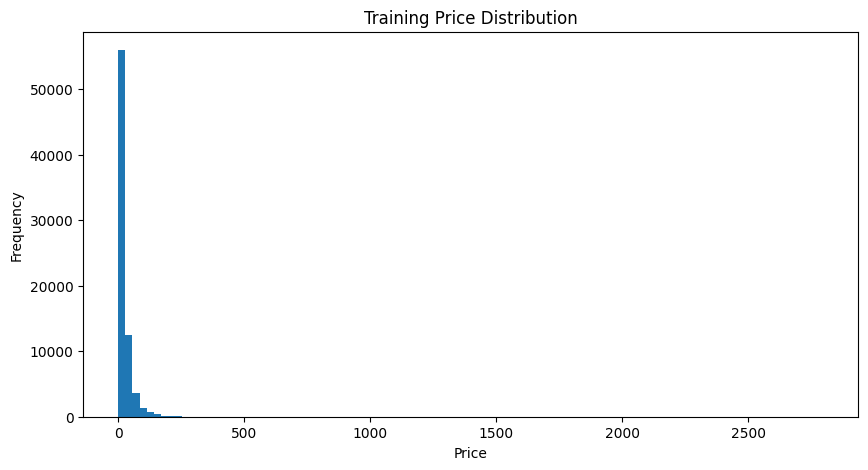

In [11]:
plt.figure(figsize=(10, 5))
plt.hist(price, bins=100)
plt.title('Training Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

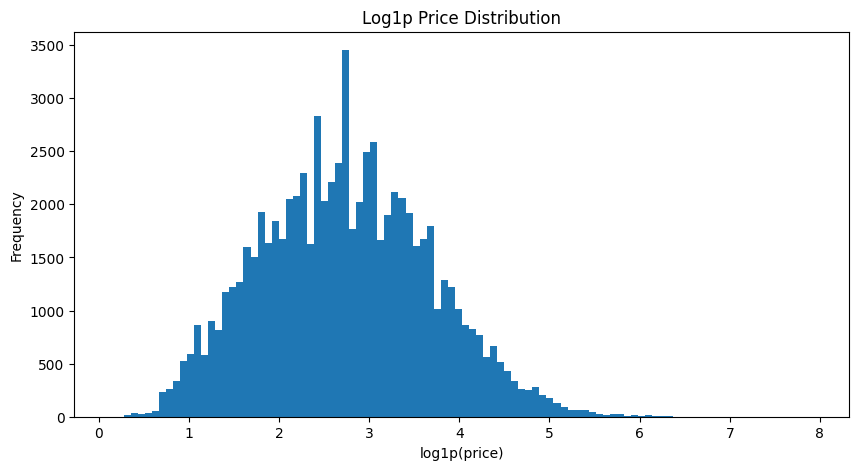

In [12]:
log_price = np.log1p(price)

plt.figure(figsize=(10, 5))
plt.hist(log_price, bins=100)
plt.title('Log1p Price Distribution')
plt.xlabel('log1p(price)')
plt.ylabel('Frequency')
plt.show()

## 11. Catalog Content Analysis

In [13]:
for df in (train_df, test_df):
    text = df['catalog_content'].fillna('').astype(str)
    df['catalog_char_count'] = text.str.len()
    df['catalog_word_count'] = text.str.split().str.len()
    df['catalog_digit_count'] = text.str.count(r'\d')

text_stats = pd.DataFrame({
    'train_char_count': train_df['catalog_char_count'].describe(),
    'test_char_count': test_df['catalog_char_count'].describe(),
    'train_word_count': train_df['catalog_word_count'].describe(),
    'test_word_count': test_df['catalog_word_count'].describe(),
})

display(text_stats)

,train_char_count,test_char_count,train_word_count,test_word_count
count,75000.000000,75000.000000,75000.000000,75000.000000
mean,908.886547,910.762947,147.851693,148.145907
std,852.896151,857.030190,137.068731,137.760572
min,32.000000,37.000000,7.000000,7.000000
25%,251.000000,252.000000,42.000000,42.000000
50%,643.000000,636.000000,104.000000,103.000000
75%,1280.000000,1288.000000,208.000000,210.000000
max,7894.000000,11136.000000,1333.000000,1928.000000


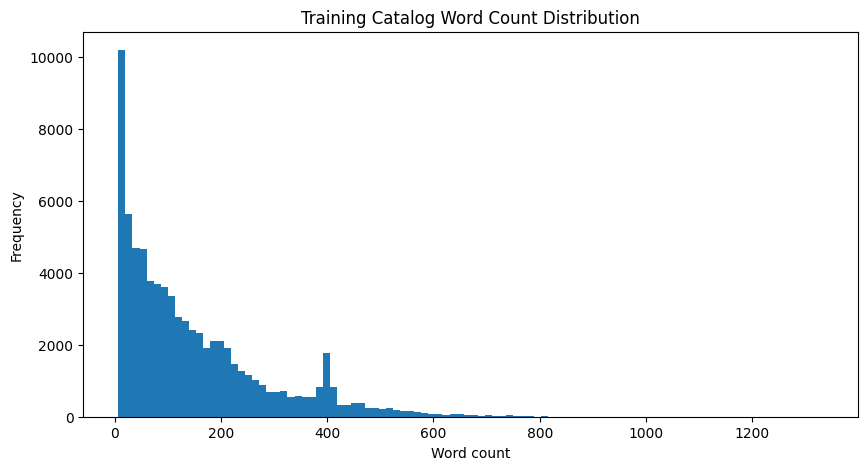

In [14]:
plt.figure(figsize=(10, 5))
plt.hist(train_df['catalog_word_count'], bins=100)
plt.title('Training Catalog Word Count Distribution')
plt.xlabel('Word count')
plt.ylabel('Frequency')
plt.show()

## 12. Inspect Longest and Shortest Catalog Entries

In [15]:
display(
    train_df.nlargest(5, 'catalog_word_count')[
        ['sample_id', 'catalog_word_count', 'price', 'catalog_content']
    ]
)

display(
    train_df.nsmallest(5, 'catalog_word_count')[
        ['sample_id', 'catalog_word_count', 'price', 'catalog_content']
    ]
)

,sample_id,catalog_word_count,price,catalog_content
37081,124301,1333,8.99,"Item Name: Akshit Dried Papaya Leaves, Leaf Tea, Hojas De Papaya, Natural Dried Leaf, Loose Leaves, Non GMO, No Additives, Caffeine Free. 2.6oz\nBullet Point 1: NATURAL DRIED L..."
12476,217660,1188,16.99,"Item Name: 4E's Novelty Fruit Slices Candy -125 Pcs Bulk 1.1 lb Bag of Individually Wrapped Candy Fruit Slices,Hard Candies Assortment - for Candy Buffet, Office Candy, Christm..."
54576,210208,1138,149.00,Item Name: Ultimate 120-Serving Emergency Meal Kit | 25-Year Shelf Life | High-Calorie Survival Food Made in USA\nBullet Point 1: Homestead Cream of Wheat (20 servings) Begin y...
8326,234974,1043,12.99,Item Name: 1 Pound Light Green Sprinkles BULK Jimmies - Edible Cake Cupcakes Dessert & Ice Cream Topping-Lime Green Sprinkles\nBullet Point 1: ELEVATE YOUR DESSERTS WITH DELICI...
23789,115138,1034,27.50,"Item Name: Raw Revolution, Glo, Peanut Butter Dark Chocolate & Sea Salt, 12 Bars, 1.6 oz\nProduct Description: The Original Peanut Butter Dark Chocolate & Sea Salt bar is back ..."


,sample_id,catalog_word_count,price,catalog_content
1807,43149,7,16.95,Item Name: 1\nValue: 18.0\nUnit: Ounce\n
9841,161992,7,53.20,"Item Name: Pasta,Spaghetti\nValue: 320.0\nUnit: Ounce\n"
14876,171595,7,2.29,Item Name: 1\nValue: 96.0\nUnit: Ounce\n
15320,230528,7,13.92,Item Name: Lucky\nValue: 22.0\nUnit: Ounce\n
35312,219836,7,1.79,Item Name: Campbell's\nValue: nan\nUnit: None\n


## 13. Local Image Inventory

In [16]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp'}

train_image_paths = [
    p for p in TRAIN_IMAGE_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

test_image_paths = [
    p for p in TEST_IMAGE_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print('Train image files:', len(train_image_paths))
print('Test image files :', len(test_image_paths))

print('\nExample train filenames:')
for p in train_image_paths[:10]:
    print(p.name)

print('\nExample test filenames:')
for p in test_image_paths[:10]:
    print(p.name)

Train image files: 72287
Test image files : 72552

Example train filenames:
61UxD42OI+L.jpg
610dXMjpLRL.jpg
71PALDuk31L.jpg
819+BbUA1eL.jpg
81Ci+-P5dPL.jpg
81kCBvgvMIL.jpg
8156FrgU7hL.jpg
71NMjBu1bDL.jpg
71uBesg4e8S.jpg
81Rba1lxc0L.jpg

Example test filenames:
71mg6OgWdsL.jpg
41uOjXWR4dL.jpg
71E4xP4vNPL.jpg
91mNsN3DRSL.jpg
71PALDuk31L.jpg
81dplgdjWiL.jpg
71VfRPvssUL.jpg
91A7FCEFJeL.jpg
61M8Pnl+YCL.jpg
71PRKPJ8HoL.jpg


## 14. Inspect CSV Image Links and Infer Filename Mapping

Amazon image URLs usually end with an image filename. This section checks whether those filenames exist locally.

In [17]:
def filename_from_url(url):
    if pd.isna(url):
        return None
    return Path(urlparse(str(url)).path).name

train_df['image_filename'] = train_df['image_link'].map(filename_from_url)
test_df['image_filename'] = test_df['image_link'].map(filename_from_url)

display(train_df[['sample_id', 'image_link', 'image_filename']].head(10))

,sample_id,image_link,image_filename
0,33127,https://m.media-amazon.com/images/I/51mo8htwTHL.jpg,51mo8htwTHL.jpg
1,198967,https://m.media-amazon.com/images/I/71YtriIHAAL.jpg,71YtriIHAAL.jpg
2,261251,https://m.media-amazon.com/images/I/51+PFEe-w-L.jpg,51+PFEe-w-L.jpg
3,55858,https://m.media-amazon.com/images/I/41mu0HAToDL.jpg,41mu0HAToDL.jpg
4,292686,https://m.media-amazon.com/images/I/41sA037+QvL.jpg,41sA037+QvL.jpg
5,9259,https://m.media-amazon.com/images/I/81nw0HXpCRL.jpg,81nw0HXpCRL.jpg
6,191846,https://m.media-amazon.com/images/I/61dH2Ebkt0L.jpg,61dH2Ebkt0L.jpg
7,222007,https://m.media-amazon.com/images/I/71JllaFpxML.jpg,71JllaFpxML.jpg
8,37614,https://m.media-amazon.com/images/I/21O9RftI2vL.jpg,21O9RftI2vL.jpg
9,238044,https://m.media-amazon.com/images/I/41miQk+RkJL.jpg,41miQk+RkJL.jpg


In [18]:
train_local_names = {p.name for p in train_image_paths}
test_local_names = {p.name for p in test_image_paths}

train_df['local_image_exists'] = train_df['image_filename'].isin(train_local_names)
test_df['local_image_exists'] = test_df['image_filename'].isin(test_local_names)

mapping_summary = pd.DataFrame({
    'split': ['train', 'test'],
    'rows': [len(train_df), len(test_df)],
    'mapped_images': [train_df['local_image_exists'].sum(), test_df['local_image_exists'].sum()],
    'missing_images': [(~train_df['local_image_exists']).sum(), (~test_df['local_image_exists']).sum()],
    'mapping_pct': [
        train_df['local_image_exists'].mean() * 100,
        test_df['local_image_exists'].mean() * 100,
    ]
})

display(mapping_summary)

,split,rows,mapped_images,missing_images,mapping_pct
0,train,75000,74999,1,99.998667
1,test,75000,74999,1,99.998667


## 15. Inspect Missing Image Mappings

In [19]:
train_missing_images = train_df.loc[
    ~train_df['local_image_exists'],
    ['sample_id', 'image_link', 'image_filename']
]

test_missing_images = test_df.loc[
    ~test_df['local_image_exists'],
    ['sample_id', 'image_link', 'image_filename']
]

print('Train missing mappings:', len(train_missing_images))
display(train_missing_images.head(20))

print('Test missing mappings:', len(test_missing_images))
display(test_missing_images.head(20))

Train missing mappings: 1


,sample_id,image_link,image_filename
38945,279285,https://m.media-amazon.com/images/I/51mjZYDYjyL.jpg,51mjZYDYjyL.jpg


Test missing mappings: 1


,sample_id,image_link,image_filename
42045,286800,https://m.media-amazon.com/images/I/813CjSgHj0S.jpg,813CjSgHj0S.jpg


## 16. Basic Image Integrity Check

Checking every image can take some time. We first verify a sample of images. Increase `IMAGE_CHECK_SAMPLE` later if needed.

In [20]:
IMAGE_CHECK_SAMPLE = 1000

def verify_images(paths, max_images=1000):
    corrupted = []
    checked = 0
    
    for path in tqdm(paths[:max_images]):
        try:
            with Image.open(path) as img:
                img.verify()
            checked += 1
        except Exception as exc:
            corrupted.append((str(path), str(exc)))
    
    return checked, corrupted

train_checked, train_corrupted = verify_images(train_image_paths, IMAGE_CHECK_SAMPLE)
test_checked, test_corrupted = verify_images(test_image_paths, IMAGE_CHECK_SAMPLE)

print(f'Train images checked: {train_checked}, corrupted: {len(train_corrupted)}')
print(f'Test images checked : {test_checked}, corrupted: {len(test_corrupted)}')

if train_corrupted:
    display(pd.DataFrame(train_corrupted, columns=['path', 'error']).head(20))

if test_corrupted:
    display(pd.DataFrame(test_corrupted, columns=['path', 'error']).head(20))

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 4661.70it/s]

Train images checked: 1000, corrupted: 0
Test images checked : 1000, corrupted: 0


## 17. Sample Submission Validation

In [21]:
print('Sample test columns  :', sample_test_df.columns.tolist())
print('Sample output columns:', sample_out_df.columns.tolist())

display(sample_out_df.head())

assert list(sample_out_df.columns) == ['sample_id', 'price'], (
    'sample_test_out.csv should contain exactly sample_id and price.'
)

assert len(sample_test_df) == len(sample_out_df), (
    'sample_test.csv and sample_test_out.csv row counts do not match.'
)

print('Sample submission format validation passed.')

Sample test columns  : ['sample_id', 'catalog_content', 'image_link']
Sample output columns: ['sample_id', 'price']


,sample_id,price
0,217392,62.080008
1,209156,17.189763
2,262333,96.501410
3,295979,5.652474
4,50604,23.794780


Sample submission format validation passed.


## 18. Create Dataset Profile Artifact

In [22]:
profile = {
    'train_rows': int(len(train_df)),
    'test_rows': int(len(test_df)),
    'train_columns': train_df.columns.tolist(),
    'test_columns': test_df.columns.tolist(),
    'train_unique_sample_ids': int(train_df['sample_id'].nunique()),
    'test_unique_sample_ids': int(test_df['sample_id'].nunique()),
    'train_missing_values': {k: int(v) for k, v in train_df.isna().sum().items()},
    'test_missing_values': {k: int(v) for k, v in test_df.isna().sum().items()},
    'price_min': float(price.min()),
    'price_max': float(price.max()),
    'price_mean': float(price.mean()),
    'price_median': float(price.median()),
    'price_std': float(price.std()),
    'train_image_files': int(len(train_image_paths)),
    'test_image_files': int(len(test_image_paths)),
    'train_mapped_images': int(train_df['local_image_exists'].sum()),
    'test_mapped_images': int(test_df['local_image_exists'].sum()),
    'train_missing_image_mappings': int((~train_df['local_image_exists']).sum()),
    'test_missing_image_mappings': int((~test_df['local_image_exists']).sum()),
    'train_duplicate_catalog_content': int(train_df['catalog_content'].duplicated().sum()),
    'test_duplicate_catalog_content': int(test_df['catalog_content'].duplicated().sum()),
}

PROFILE_PATH = ARTIFACTS_DIR / 'data_profile.json'
with PROFILE_PATH.open('w') as f:
    json.dump(profile, f, indent=2)

print('Saved dataset profile to:', PROFILE_PATH)
display(pd.Series(profile, name='value').to_frame())

Saved dataset profile to: /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/artifacts/data_profile.json


,value
train_rows,75000
test_rows,75000
train_columns,"[sample_id, catalog_content, image_link, price, catalog_char_count, catalog_word_count, catalog_digit_count, image_filename, local_image_exists]"
test_columns,"[sample_id, catalog_content, image_link, catalog_char_count, catalog_word_count, catalog_digit_count, image_filename, local_image_exists]"
train_unique_sample_ids,75000
test_unique_sample_ids,75000
train_missing_values,"{'sample_id': 0, 'catalog_content': 0, 'image_link': 0, 'price': 0, 'catalog_char_count': 0, 'catalog_word_count': 0, 'catalog_digit_count': 0, 'image_filename': 0, 'local_imag..."
test_missing_values,"{'sample_id': 0, 'catalog_content': 0, 'image_link': 0, 'catalog_char_count': 0, 'catalog_word_count': 0, 'catalog_digit_count': 0, 'image_filename': 0, 'local_image_exists': 0}"
price_min,0.13
price_max,2796.0


## 19. Final V0.1 Validation Summary

In [23]:
print('=' * 65)
print('PRICEFUSION V0.1 — DATASET VALIDATION COMPLETE')
print('=' * 65)
print(f'Train rows                  : {len(train_df):,}')
print(f'Test rows                   : {len(test_df):,}')
print(f'Train image files           : {len(train_image_paths):,}')
print(f'Test image files            : {len(test_image_paths):,}')
print(f'Train missing image mappings: {(~train_df["local_image_exists"]).sum():,}')
print(f'Test missing image mappings : {(~test_df["local_image_exists"]).sum():,}')
print(f'Minimum price               : {price.min():.4f}')
print(f'Median price                : {price.median():.4f}')
print(f'Maximum price               : {price.max():.4f}')
print('=' * 65)
print('Next milestone: PriceFusion V0.2 — Exploratory Data Analysis')

PRICEFUSION V0.1 — DATASET VALIDATION COMPLETE
Train rows                  : 75,000
Test rows                   : 75,000
Train image files           : 72,287
Test image files            : 72,552
Train missing image mappings: 1
Test missing image mappings : 1
Minimum price               : 0.1300
Median price                : 14.0000
Maximum price               : 2796.0000
Next milestone: PriceFusion V0.2 — Exploratory Data Analysis
